# Experiment 2: Data Cleaning and Transformation

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
np.random.seed(42)

## Load dataset

In [2]:
df = sns.load_dataset("titanic")
raw_shape = df.shape
display(df.head())

print("Shape:", df.shape)
df.info()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


## Detect missing values

,missing,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


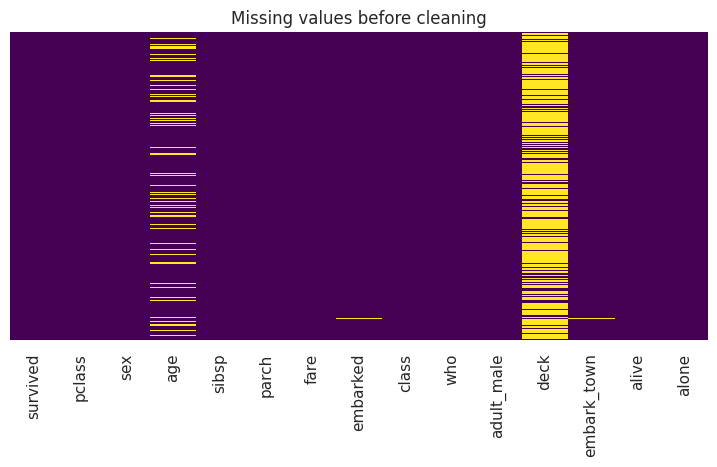

In [3]:
missing = pd.DataFrame({"missing": df.isnull().sum(), "percent": (df.isnull().mean() * 100).round(2)})
display(missing[missing["missing"] > 0].sort_values("missing", ascending=False))

plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values before cleaning")
plt.show()

## Detect and remove duplicates

In [4]:
print("Duplicate rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Duplicate rows: 107


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


Shape after removing duplicates: (784, 15)
Duplicate rows remaining: 0


## Handle missing values

In [5]:
df = df.drop(columns=["deck"])
display(df.shape)

df["age"] = df["age"].fillna(df.groupby(["pclass", "sex"])["age"].transform("median"))
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])
display(df.isnull().sum())

print("Total missing values remaining:", df.isnull().sum().sum())

(784, 14)

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

Total missing values remaining: 0


## Fix data types and inconsistencies

In [6]:
df["sex"] = df["sex"].astype("category")
df["embarked"] = df["embarked"].astype("category")
df["pclass"] = df["pclass"].astype("category")
df["survived"] = df["survived"].astype(int)
df["age"] = df["age"].round(0).astype(int)
df.dtypes

survived          int64
pclass         category
sex            category
age               int64
sibsp             int64
parch             int64
fare            float64
embarked       category
class          category
who                 str
adult_male         bool
embark_town         str
alive               str
alone              bool
dtype: object

## Outlier detection and treatment

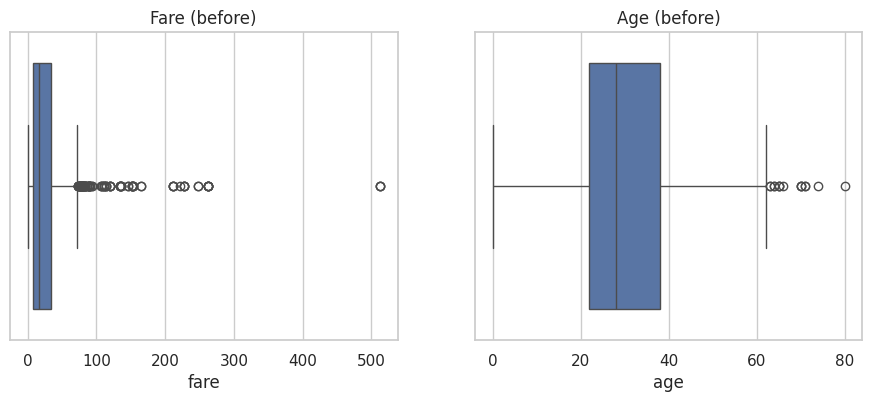

Fare fences: -31.04 to 73.20
Outliers in fare: 102
Max fare before: 512.3292 | after capping: 73.198375


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(x=df["fare"], ax=axes[0])
axes[0].set_title("Fare (before)")
sns.boxplot(x=df["age"], ax=axes[1])
axes[1].set_title("Age (before)")
plt.show()

q1, q3 = df["fare"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Fare fences: {low:.2f} to {high:.2f}")
print("Outliers in fare:", ((df["fare"] < low) | (df["fare"] > high)).sum())

df["fare_capped"] = df["fare"].clip(lower=low, upper=high)
print("Max fare before:", df["fare"].max(), "| after capping:", df["fare_capped"].max())

## Transformations of skewed data

Box-Cox lambda: -0.11


,skewness
original,4.571
capped,1.097
sqrt,2.026
log1p,0.416
box-cox,-0.038


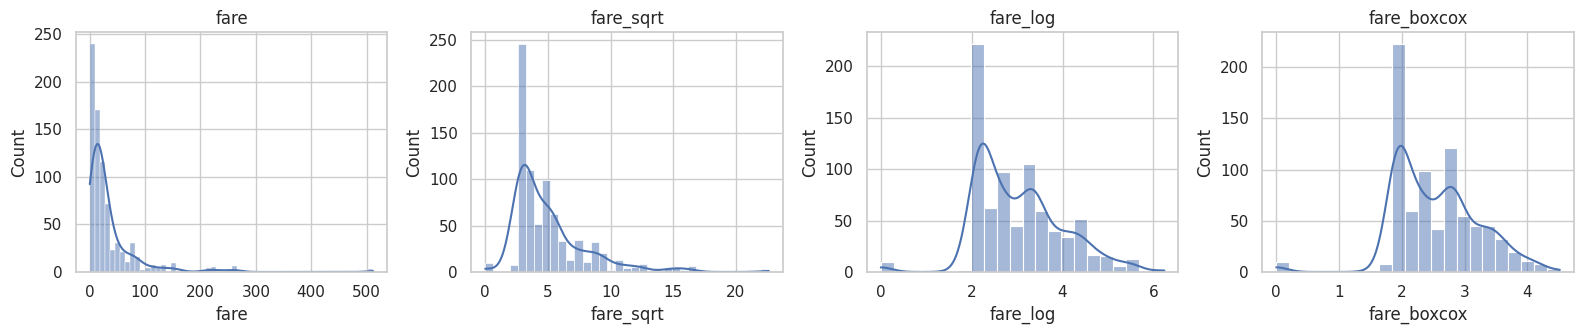

In [8]:
df["fare_log"] = np.log1p(df["fare"])
df["fare_sqrt"] = np.sqrt(df["fare"])
df["fare_boxcox"], lam = stats.boxcox(df["fare"] + 1)
print("Box-Cox lambda:", round(lam, 4))

skew = pd.Series({
    "original": df["fare"].skew(),
    "capped": df["fare_capped"].skew(),
    "sqrt": df["fare_sqrt"].skew(),
    "log1p": df["fare_log"].skew(),
    "box-cox": pd.Series(df["fare_boxcox"]).skew(),
})
display(skew.round(3).to_frame("skewness"))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, ["fare", "fare_sqrt", "fare_log", "fare_boxcox"]):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Binning (discretisation)

In [9]:
df["age_group"] = pd.cut(df["age"], bins=[0, 12, 18, 35, 60, 100], labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
df["fare_quartile"] = pd.qcut(df["fare"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
display(df[["age", "age_group", "fare", "fare_quartile"]].head(8))

df["age_group"].value_counts().sort_index()

,age,age_group,fare,fare_quartile
0,22,Young Adult,7.2500,Q1
1,38,Adult,71.2833,Q4
2,26,Young Adult,7.9250,Q1
3,35,Young Adult,53.1000,Q4
4,35,Young Adult,8.0500,Q1
5,25,Young Adult,8.4583,Q2
6,54,Adult,51.8625,Q4
7,2,Child,21.0750,Q3


age_group
Child           67
Teen            67
Young Adult    415
Adult          212
Senior          22
Name: count, dtype: int64

## Feature engineering

In [10]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["is_alone"] = (df["family_size"] == 1).astype(int)
df[["sibsp", "parch", "family_size", "is_alone"]].head()

,sibsp,parch,family_size,is_alone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


## Encoding categorical variables

In [11]:
df["sex_encoded"] = df["sex"].map({"male": 0, "female": 1}).astype(int)
df["age_group_encoded"] = df["age_group"].cat.codes
display(df[["sex", "sex_encoded", "age_group", "age_group_encoded"]].head())

df_encoded = pd.get_dummies(df, columns=["embarked", "pclass"], prefix=["emb", "cls"], drop_first=True, dtype=int)
df_encoded.filter(regex="^(emb|cls)").head()

,sex,sex_encoded,age_group,age_group_encoded
0,male,0,Young Adult,2
1,female,1,Adult,3
2,female,1,Young Adult,2
3,female,1,Young Adult,2
4,male,0,Young Adult,2


,embark_town,emb_Q,emb_S,cls_2,cls_3
0,Southampton,0,1,0,1
1,Cherbourg,0,0,0,0
2,Southampton,0,1,0,1
3,Southampton,0,1,0,0
4,Southampton,0,1,0,1


## Normalisation of numeric columns

In [12]:
df["age_minmax"] = (df["age"] - df["age"].min()) / (df["age"].max() - df["age"].min())
df["fare_zscore"] = (df["fare_capped"] - df["fare_capped"].mean()) / df["fare_capped"].std()
df[["age", "age_minmax", "fare_capped", "fare_zscore"]].describe().round(3)

,age,age_minmax,fare_capped,fare_zscore
count,784.000,784.000,784.000,784.000
mean,29.636,0.370,26.493,-0.000
std,13.950,0.174,22.762,1.000
min,0.000,0.000,0.000,-1.164
25%,22.000,0.275,8.050,-0.810
50%,28.000,0.350,15.900,-0.465
75%,38.000,0.475,34.109,0.335
max,80.000,1.000,73.198,2.052


## Before vs after comparison

Raw shape: (891, 15)
Cleaned shape: (784, 26)
Encoded shape: (784, 26)
Missing values: 1
Duplicates: 15


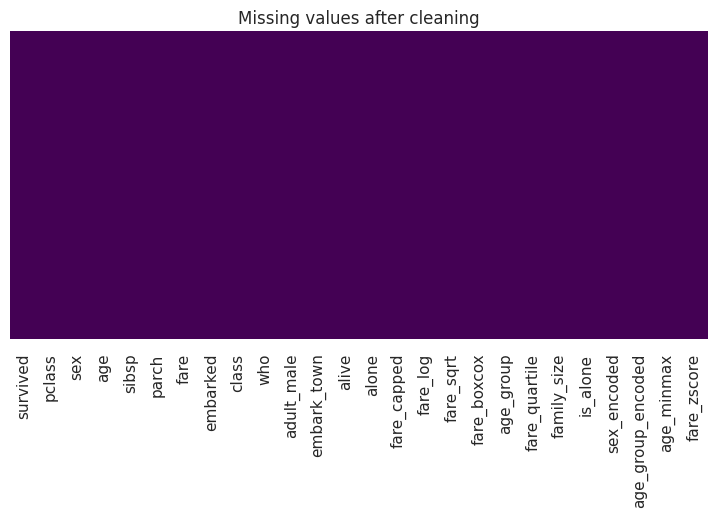

,survived,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,...,age_group,fare_quartile,family_size,is_alone,sex_encoded,age_group_encoded,emb_Q,emb_S,cls_2,cls_3
0,0,male,22,1,0,7.2500,Third,man,True,Southampton,...,Young Adult,Q1,2,0,0,2,0,1,0,1
1,1,female,38,1,0,71.2833,First,woman,False,Cherbourg,...,Adult,Q4,2,0,1,3,0,0,0,0
2,1,female,26,0,0,7.9250,Third,woman,False,Southampton,...,Young Adult,Q1,1,1,1,2,0,1,0,1
3,1,female,35,1,0,53.1000,First,woman,False,Southampton,...,Young Adult,Q4,2,0,1,2,0,1,0,0
4,0,male,35,0,0,8.0500,Third,man,True,Southampton,...,Young Adult,Q1,1,1,0,2,0,1,0,1


In [13]:
print("Raw shape:", raw_shape)
print("Cleaned shape:", df.shape)
print("Encoded shape:", df_encoded.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

plt.figure(figsize=(9, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing values after cleaning")
plt.show()

df_encoded.head()